<a href="https://colab.research.google.com/github/siaelkhattat/NeuralMachineTranslation/blob/main/02_baseline_method_A.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Phase 2 — Baseline (Method A)
**Method A** = the pretrained Marian model `Helsinki-NLP/opus-mt-ar-en`, fine-tuned on our Darija (Latin script) → English pairs with the standard word-by-word loss (cross-entropy). Nothing syntactic yet.

**What this notebook produces**
1. **Tokenization diagnostics:** does the Arabic-trained tokenizer cope with Latin-script Darija?
2. **A0:** the pretrained model with no fine-tuning (lower bound).
3. **A1:** the fine-tuned model, 3 seeds, early stopping on dev chrF++. These checkpoints are the starting point of Method B in Phase 6.
4. Results table (dev and test), significance test A0 vs A1, error analysis, optional learning curve.

**Runtime:** GPU (Runtime → Change runtime type → T4 GPU). **First run with `SMOKE = True`** (cell 3): a tiny run that finishes in minutes and shows whether everything works. Then set `SMOKE = False` and re-run from cell 3.

**Rules we follow:** dev is used for choosing checkpoints, **test is used only for final numbers**; the training loop is written by hand (no `Trainer`) because Phase 6 needs a custom loss and this avoids library-version surprises.

In [1]:
# 1. Setup -------------------------------------------------------------------
!pip -q install transformers sentencepiece sacrebleu

import os, re, json, time, math, random, platform, datetime, shutil, subprocess
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn.functional as F
try:
    from IPython.display import display
except ImportError:
    display = print

try:
    from google.colab import drive, userdata
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    drive.mount('/content/drive')
    BASE = '/content/drive/MyDrive/NeuralMachineTranslation'
    REPO_DIR = '/content/NeuralMachineTranslation'
else:
    BASE, REPO_DIR = './NeuralMachineTranslation_drive', './NeuralMachineTranslation'
DATA_DIR = f'{BASE}/data'                 # Phase 1 output (train/dev/test .jsonl)
RUN_ROOT = f'{BASE}/runs/phase2'          # checkpoints and predictions (big, stays on Drive)
REPORT_DIR = f'{REPO_DIR}/reports/phase2' # small tables and figures (go to GitHub)

assert torch.cuda.is_available(), 'No GPU: Runtime > Change runtime type > T4 GPU'
DEVICE = torch.device('cuda')
print('GPU:', torch.cuda.get_device_name(0), '| torch', torch.__version__)
import transformers; print('transformers', transformers.__version__)

Mounted at /content/drive
GPU: Tesla T4 | torch 2.14.1+cu130
transformers 5.22.1


In [2]:
# 2. Clone the GitHub

if IN_COLAB:
    # Clone the public GitHub repository if it doesn't exist
    if not os.path.exists(f'{REPO_DIR}/.git'):
        !rm -rf {REPO_DIR}
        !git clone https://github.com/siaelkhattat/NeuralMachineTranslation.git {REPO_DIR}



Cloning into '/content/NeuralMachineTranslation'...
remote: Enumerating objects: 26, done.
remote: Counting objects: 100% (26/26), done.
remote: Compressing objects: 100% (24/24), done.
remote: Total 26 (delta 2), reused 13 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (26/26), 155.73 KiB | 19.47 MiB/s, done.
Resolving deltas: 100% (2/2), done.


In [7]:
# 3. Configuration ---------------------------------------------------------------------
SMOKE = False        # True: tiny test run (minutes). False: the real experiment.

CFG = dict(
    model_name='Helsinki-NLP/opus-mt-ar-en',
    seeds=[13, 42, 2024],
    max_src_len=64, max_tgt_len=64,          # tokens; checked against the percentiles in cell 6
    batch_size=32, grad_accum=1,
    lr=5e-5, weight_decay=0.01, warmup_steps=200,
    max_epochs=10, patience=3,               # early stopping on dev chrF++
    label_smoothing=0.1,
    num_beams=4, max_new_tokens=64, eval_batch_size=64,
    use_amp=True,                            # fp16 on the T4
    lowercase_metrics=True,                  # DODa capitalisation is inconsistent, so scores are case-insensitive
)
N_TRAIN_LIMIT = N_DEV_LIMIT = None
RUN_DIR = RUN_ROOT
if SMOKE:
    CFG.update(seeds=[13], max_epochs=1, warmup_steps=5)
    N_TRAIN_LIMIT, N_DEV_LIMIT = 256, 128
    RUN_DIR = RUN_ROOT + '_smoke'
os.makedirs(RUN_DIR, exist_ok=True); os.makedirs(f'{RUN_DIR}/pred', exist_ok=True)
os.makedirs(REPORT_DIR, exist_ok=True); os.makedirs(f'{REPORT_DIR}/figures', exist_ok=True)
print('SMOKE =', SMOKE, '| RUN_DIR =', RUN_DIR)

SMOKE = False | RUN_DIR = /content/drive/MyDrive/NeuralMachineTranslation/runs/phase2


In [8]:
# 4. Load the Phase 1 splits -----------------------------------------------------------
def read_jsonl(p): return pd.read_json(p, lines=True)
train, dev, test = (read_jsonl(f'{DATA_DIR}/{s}.jsonl') for s in ('train', 'dev', 'test'))
print('full sizes  train/dev/test:', len(train), len(dev), len(test))
if SMOKE:
    train, dev, test = train.head(N_TRAIN_LIMIT), dev.head(N_DEV_LIMIT), test.head(N_DEV_LIMIT)
dev_src, dev_ref = dev['darija'].tolist(), dev['english'].tolist()
test_src, test_ref = test['darija'].tolist(), test['english'].tolist()
print('used sizes  train/dev/test:', len(train), len(dev), len(test))
display(train.sample(5, random_state=0)[['darija', 'english']])

full sizes  train/dev/test: 10498 2249 2249
used sizes  train/dev/test: 10498 2249 2249


,darija,english
8190,m3a deri kan smer kanou dima kaytnemrou 3lih,he is black the bully him
8172,3mri l9it b7al had naw3ia b taman mzyan,i never found a better price
8237,5atweli tchouf ga3 lfra9i baghinek yallah byen...,you will see all the fans chanting your name
5065,t3etli bezzaf bach tchri crema lwjhek,you are too late to buy sunscreen
10250,heram 3lik ntiya li mchiti khelitih,shame on you you left him


In [9]:
# 5. Helpers that do not need the GPU (metrics, statistics, significance) -------------------
from sacrebleu.metrics import BLEU, CHRF
from sacrebleu.significance import PairedTest

_bleu = BLEU(lowercase=CFG['lowercase_metrics'])
_chrf = CHRF(word_order=2, lowercase=CFG['lowercase_metrics'])      # chrF++

def score(hyps, refs):
    return dict(bleu=round(_bleu.corpus_score(hyps, [refs]).score, 2),
                chrfpp=round(_chrf.corpus_score(hyps, [refs]).score, 2))

def paired_bootstrap(refs, systems, baseline, n=1000):
    # systems: dict name -> list of hypotheses. Returns a table of scores, 95% CI and p-value vs. the baseline.
    names = [baseline] + [k for k in systems if k != baseline]
    metrics = {'BLEU': BLEU(lowercase=CFG['lowercase_metrics']), 'chrF++': CHRF(word_order=2, lowercase=CFG['lowercase_metrics'])}
    test = PairedTest(named_systems=[(k, systems[k]) for k in names], metrics=metrics, references=[refs],
                      test_type='bs', n_samples=n, n_jobs=1)
    _, scores = test()
    get = lambda s, k: s[k] if isinstance(s, dict) else getattr(s, k)       # the result type differs between sacrebleu versions
    rows = []
    for metric_name, lst in scores.items():
        if metric_name == 'System':
            continue
        for sysname, s in zip(names, lst):
            p = get(s, 'p_value')
            rows.append(dict(system=sysname, metric=metric_name, score=round(float(get(s, 'score')), 2),
                             ci95=round(float(get(s, 'ci')), 2), p_value_vs_baseline=None if p is None else round(float(p), 4)))
    return pd.DataFrame(rows)

def token_stats(tok, texts, target=False):
    ids = tok(text_target=list(texts))['input_ids'] if target else tok(list(texts))['input_ids']
    lens = np.array([len(x) for x in ids])
    n_unk = sum(sum(1 for t in x if t == tok.unk_token_id) for x in ids)
    words = sum(len(t.split()) for t in texts)
    return dict(mean_len=round(float(lens.mean()), 1), p95=float(np.percentile(lens, 95)), p99=float(np.percentile(lens, 99)),
                max=int(lens.max()), unk_rate_pct=round(100 * n_unk / int(lens.sum()), 3),
                tokens_per_word=round(float(lens.sum() / words), 2)), ids

def sentence_chrf(h, r): return _chrf.sentence_score(h, [r]).score

def bucket_table(src, hyps, refs, edges=(0, 6, 8, 10, 13, 999)):   # sentences are short: about 7 words on average
    nw = np.array([len(s.split()) for s in src]); rows = []
    for lo, hi in zip(edges[:-1], edges[1:]):
        idx = np.where((nw >= lo) & (nw < hi))[0]
        if len(idx) >= 5:
            sc = score([hyps[i] for i in idx], [refs[i] for i in idx])
            rows.append(dict(source_words=f'{lo}-{hi - 1}' if hi < 999 else f'{lo}+', n=len(idx), **sc))
    return pd.DataFrame(rows)

def degenerate_stats(src, hyps, refs):
    def repeats(h):
        w = h.lower().split()
        tri = [tuple(w[i:i + 3]) for i in range(len(w) - 2)]
        return len(tri) > 0 and max(tri.count(t) for t in set(tri)) >= 3
    n = len(hyps)
    return dict(empty_pct=round(100 * sum(h.strip() == '' for h in hyps) / n, 2),
                copy_of_source_pct=round(100 * sum(h.strip().lower() == s.strip().lower() for h, s in zip(hyps, src)) / n, 2),
                repeated_trigram_pct=round(100 * sum(repeats(h) for h in hyps) / n, 2),
                hyp_over_ref_length=round(sum(len(h.split()) for h in hyps) / max(1, sum(len(r.split()) for r in refs)), 3))

def md_table(df):
    d = df.reset_index(drop=True)
    return '| ' + ' | '.join(map(str, d.columns)) + ' |\n|' + '---|' * len(d.columns) + '\n' + '\n'.join('| ' + ' | '.join(map(str, r)) + ' |' for r in d.values)

/usr/local/lib/python3.13/dist-packages/transformers/models/marian/tokenization_marian.py:176: UserWarning: Recommended: pip install sacremoses.
  warnings.warn("Recommended: pip install sacremoses.")


vocabulary size of the tokenizer: 62834 | unk token id: 1


,mean_len,p95,p99,max,unk_rate_pct,tokens_per_word
Darija (source),23.1,37.0,47.0,91,0.000,3.35
English (target),10.1,17.0,22.0,43,0.003,1.32


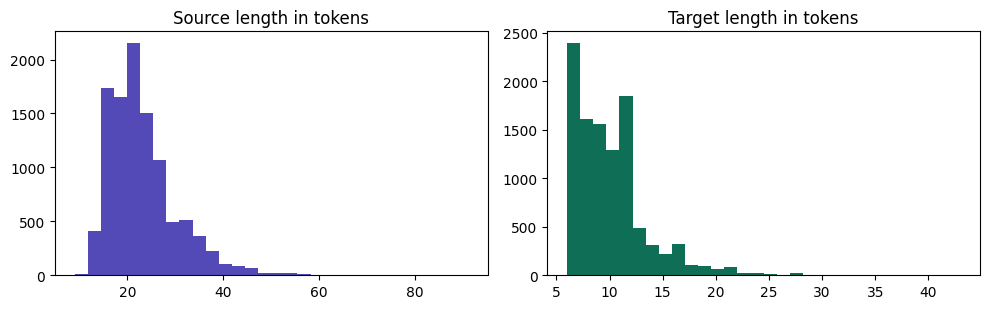


How five training sentences are cut into pieces (look for a very fragmented source side):
   homa mkhbbyin chi haja, ana mti99en!
   -> ['▁h', 'oma', '▁m', 'k', 'h', 'bb', 'y', 'in', '▁', 'chi', '▁', 'ha', 'ja', ',', '▁', 'ana', '▁m', 'ti', '99', 'en', '!', '</s>']
   loTilat mabaynach fihom mori7in bzzaf.
   -> ['▁', 'lo', 'T', 'il', 'at', '▁', 'ma', 'ba', 'yn', 'ach', '▁', 'fi', 'ho', 'm', '▁mo', 'ri', '7', 'in', '▁b', 'z', 'za', 'f', '.', '</s>']
   bghit n3ref ch7al b9a lia tlwe9t bach n9ra
   -> ['▁b', 'g', 'h', 'it', '▁n', '3', 're', 'f', '▁', 'ch', '7', 'al', '▁b', '9', 'a', '▁', 'lia', '▁t', 'l', 'we', '9', 't', '▁b', 'ach', '▁n', '9', 'ra', '</s>']
   ghaykon 3ndna mti7an, ala hadchi lli 9Sedti
   -> ['▁g', 'ha', 'y', 'k', 'on', '▁3', 'nd', 'na', '▁m', 'ti', '7', 'an', ',', '▁', 'ala', '▁had', 'chi', '▁l', 'li', '▁9', 'S', 'ed', 'ti', '</s>']
   ghanghTTiw ga3 lmawad tal tlat jjay
   -> ['▁g', 'h', 'ang', 'h', 'T', 'T', 'i', 'w', '▁', 'ga', '3', '▁l', 'ma', 'w', 'ad', '▁t', '

In [10]:
# 6. Tokenization diagnostics: can an Arabic-trained tokenizer read Latin-script Darija? ----------------
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM, get_linear_schedule_with_warmup
tok = AutoTokenizer.from_pretrained(CFG['model_name'])
print('vocabulary size of the tokenizer:', len(tok), '| unk token id:', tok.unk_token_id)

ss, src_ids = token_stats(tok, train['darija'])
st, tgt_ids = token_stats(tok, train['english'], target=True)
diag = pd.DataFrame([ss, st], index=['Darija (source)', 'English (target)'])
display(diag)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].hist([len(x) for x in src_ids], bins=30, color='#534AB7'); ax[0].set_title('Source length in tokens')
ax[1].hist([len(x) for x in tgt_ids], bins=30, color='#0F6E56'); ax[1].set_title('Target length in tokens')
plt.tight_layout(); plt.savefig(f'{REPORT_DIR}/figures/token_lengths.png', dpi=150); plt.show()

print('\nHow five training sentences are cut into pieces (look for a very fragmented source side):')
for i in range(5):
    print('  ', train['darija'].iloc[i]); print('   ->', tok.convert_ids_to_tokens(src_ids[i]))
diag.to_csv(f'{REPORT_DIR}/tokenization_diagnostics.csv')
print('\nThings to check: unk_rate_pct should stay low (a few percent would be worrying), tokens_per_word on the source side is the')
print('fragmentation (about 1.3-2 is normal, above ~3.5 means the tokenizer is breaking Latin Darija into characters),')
print('and p99 should be below max_src_len / max_tgt_len in the configuration.')

In [11]:
# 7. Model helpers (need the GPU) -------------------------------------------------------------------------
from torch.utils.data import DataLoader
from torch.optim import AdamW

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

def translate(model, tok, sources, batch_size=None, num_beams=None, max_new_tokens=None):
    batch_size = batch_size or CFG['eval_batch_size']; num_beams = num_beams or CFG['num_beams']
    max_new_tokens = max_new_tokens or CFG['max_new_tokens']
    model.eval()
    order = np.argsort([-len(s) for s in sources]); out = [None] * len(sources)
    with torch.no_grad():
        for i in range(0, len(order), batch_size):
            idx = order[i:i + batch_size]
            enc = tok([sources[j] for j in idx], return_tensors='pt', padding=True, truncation=True,
                      max_length=CFG['max_src_len']).to(DEVICE)
            with torch.autocast('cuda', dtype=torch.float16, enabled=CFG['use_amp']):
                gen = model.generate(**enc, num_beams=num_beams, max_new_tokens=max_new_tokens)
            for j, d in zip(idx, tok.batch_decode(gen, skip_special_tokens=True)):
                out[j] = d.strip()
    return out

def encode_pairs(tok, src_texts, tgt_texts):
    s = tok(list(src_texts), truncation=True, max_length=CFG['max_src_len'])['input_ids']
    t = tok(text_target=list(tgt_texts), truncation=True, max_length=CFG['max_tgt_len'])['input_ids']
    return list(zip(s, t))

def make_collate(pad_id):
    def collate(batch):
        ms, mt = max(len(s) for s, _ in batch), max(len(t) for _, t in batch)
        src = torch.full((len(batch), ms), pad_id, dtype=torch.long)
        att = torch.zeros((len(batch), ms), dtype=torch.long)
        lab = torch.full((len(batch), mt), -100, dtype=torch.long)
        for i, (s, t) in enumerate(batch):
            src[i, :len(s)] = torch.tensor(s); att[i, :len(s)] = 1; lab[i, :len(t)] = torch.tensor(t)
        return src, att, lab
    return collate

def save_preds(hyps, name):
    with open(f'{RUN_DIR}/pred/{name}.txt', 'w', encoding='utf-8') as f:
        f.write('\n'.join(hyps) + '\n')

def train_one_seed(seed, n_train=None, tag='A1'):
    out_dir = f'{RUN_DIR}/{tag}_seed{seed}'; os.makedirs(out_dir, exist_ok=True)
    if os.path.exists(f'{out_dir}/result.json'):                      # resumable after a Colab disconnect
        print(f'[{tag} seed {seed}] already done, loading result'); return json.load(open(f'{out_dir}/result.json'))
    set_seed(seed)
    model = AutoModelForSeq2SeqLM.from_pretrained(CFG['model_name']).to(DEVICE)
    tr = train if n_train is None else train.sample(min(n_train, len(train)), random_state=seed)
    data = encode_pairs(tok, tr['darija'], tr['english'])
    g = torch.Generator(); g.manual_seed(seed)
    dl = DataLoader(data, batch_size=CFG['batch_size'], shuffle=True, collate_fn=make_collate(tok.pad_token_id), generator=g)
    no_decay = ('bias', 'layer_norm', 'LayerNorm')
    groups = [dict(params=[p for n, p in model.named_parameters() if not any(k in n for k in no_decay)], weight_decay=CFG['weight_decay']),
              dict(params=[p for n, p in model.named_parameters() if any(k in n for k in no_decay)], weight_decay=0.0)]
    opt = AdamW(groups, lr=CFG['lr'])
    total_steps = math.ceil(len(dl) / CFG['grad_accum']) * CFG['max_epochs']
    sched = get_linear_schedule_with_warmup(opt, CFG['warmup_steps'], total_steps)
    scaler = torch.amp.GradScaler('cuda', enabled=CFG['use_amp'])
    best, bad, step, hist, t_start = -1.0, 0, 0, [], time.time()
    best_dir = f'{out_dir}/best'
    for epoch in range(1, CFG['max_epochs'] + 1):
        model.train(); losses, t0 = [], time.time()
        for it, (src, att, lab) in enumerate(dl):
            src, att, lab = src.to(DEVICE), att.to(DEVICE), lab.to(DEVICE)
            with torch.autocast('cuda', dtype=torch.float16, enabled=CFG['use_amp']):
                logits = model(input_ids=src, attention_mask=att, labels=lab).logits
            loss = F.cross_entropy(logits.float().reshape(-1, logits.size(-1)), lab.reshape(-1),
                                   ignore_index=-100, label_smoothing=CFG['label_smoothing'])
            scaler.scale(loss / CFG['grad_accum']).backward()
            if (it + 1) % CFG['grad_accum'] == 0 or it + 1 == len(dl):
                scaler.unscale_(opt); torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True); sched.step(); step += 1
            losses.append(loss.item())
        t_train = time.time() - t0
        sc = score(translate(model, tok, dev_src), dev_ref)
        hist.append(dict(epoch=epoch, step=step, train_loss=round(float(np.mean(losses)), 4), dev_bleu=sc['bleu'],
                         dev_chrfpp=sc['chrfpp'], train_sec=round(t_train), total_sec=round(time.time() - t0)))
        print(f'[{tag} seed {seed}] epoch {epoch}: loss {hist[-1]["train_loss"]} | dev BLEU {sc["bleu"]} chrF++ {sc["chrfpp"]} | {hist[-1]["total_sec"]}s')
        if sc['chrfpp'] > best:
            best, bad, best_epoch, best_step = sc['chrfpp'], 0, epoch, step
            model.save_pretrained(best_dir); tok.save_pretrained(best_dir)
        else:
            bad += 1
            if bad >= CFG['patience']:
                print('early stop'); break
    pd.DataFrame(hist).to_csv(f'{out_dir}/history.csv', index=False)
    res = dict(tag=tag, seed=seed, n_train=len(tr), best_epoch=best_epoch, best_step=best_step, dev_chrfpp=best,
               dev_bleu=[h['dev_bleu'] for h in hist if h['epoch'] == best_epoch][0],
               minutes=round((time.time() - t_start) / 60, 1), best_dir=best_dir)
    json.dump(res, open(f'{out_dir}/result.json', 'w'), indent=2)
    del model, opt; torch.cuda.empty_cache()
    return res

def eval_checkpoint(path, srcs, refs, name):
    model = AutoModelForSeq2SeqLM.from_pretrained(path).to(DEVICE)
    hyps = translate(model, tok, srcs); save_preds(hyps, name)
    del model; torch.cuda.empty_cache()
    return hyps, score(hyps, refs)

### Choosing the pretrained model (cells 7b–7d)
The tokenizer of `opus-mt-ar-en` was built for Arabic script. Cell 6 showed that it cuts Latin-script Darija into about 3.3 pieces per word, so we compare a few candidates **on dev data** before committing. Only Marian models are tried, because their shared vocabulary of about 60k tokens keeps the Gumbel-Softmax of Phase 6 affordable (a 250k-token vocabulary would be much heavier).

In [12]:
# 7b. Compare the tokenizers of candidate models (tokenizer files only, fast) ----------------------------------------
CANDIDATES = [
    'Helsinki-NLP/opus-mt-ar-en',
    'Helsinki-NLP/opus-mt-mul-en',
    'Helsinki-NLP/opus-mt-ROMANCE-en',
    'Helsinki-NLP/opus-mt-fr-en',
]
rows = []
for name in CANDIDATES:
    try:
        t = AutoTokenizer.from_pretrained(name)
        s_, _ = token_stats(t, train['darija'])
        e_, _ = token_stats(t, train['english'], target=True)
        rows.append(dict(model=name, vocab=len(t), src_tokens_per_word=s_['tokens_per_word'], src_unk_pct=s_['unk_rate_pct'],
                         src_p99_len=s_['p99'], tgt_tokens_per_word=e_['tokens_per_word'], tgt_unk_pct=e_['unk_rate_pct']))
    except Exception as ex:
        print('skipped', name, '->', type(ex).__name__, str(ex)[:120])
cand = pd.DataFrame(rows)
display(cand); cand.to_csv(f'{REPORT_DIR}/candidate_tokenizers.csv', index=False)
# Lower src_tokens_per_word is better for the source side. The target side (English) should stay near 1.3.

/usr/local/lib/python3.13/dist-packages/transformers/models/marian/tokenization_marian.py:176: UserWarning: Recommended: pip install sacremoses.
  warnings.warn("Recommended: pip install sacremoses.")


config.json:   0%|          | 0.00/1.40k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/44.0 [00:00<?, ?B/s]

source.spm:   0%|          | 0.00/707k [00:00<?, ?B/s]

target.spm:   0%|          | 0.00/791k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.42M [00:00<?, ?B/s]

... (7 outputs left out)

source.spm:   0%|          | 0.00/802k [00:00<?, ?B/s]

target.spm:   0%|          | 0.00/778k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.34M [00:00<?, ?B/s]

,model,vocab,src_tokens_per_word,src_unk_pct,src_p99_len,tgt_tokens_per_word,tgt_unk_pct
0,Helsinki-NLP/opus-mt-ar-en,62834,3.35,0.0,47.00,1.32,0.003
1,Helsinki-NLP/opus-mt-mul-en,64172,2.79,0.0,39.00,1.28,0.000
2,Helsinki-NLP/opus-mt-ROMANCE-en,65001,3.01,0.0,42.03,1.28,0.003
3,Helsinki-NLP/opus-mt-fr-en,59514,2.99,0.0,42.00,1.28,0.003


In [13]:
# 7c. Pilot: a short fine-tuning run per candidate, judged on DEV chrF++ (one seed, 3 epochs) -------------------------
PILOT_EPOCHS = 3

def run_pilot(model_name, epochs=PILOT_EPOCHS, seed=13):
    global tok
    old = dict(model_name=CFG['model_name'], max_epochs=CFG['max_epochs'], patience=CFG['patience'])
    CFG.update(model_name=model_name, max_epochs=epochs, patience=epochs)
    tok = AutoTokenizer.from_pretrained(model_name)
    try:
        r = train_one_seed(seed, tag='PILOT_' + model_name.split('/')[-1])
    finally:
        CFG.update(old)
    shutil.rmtree(r['best_dir'], ignore_errors=True)               # the pilot weights are not needed afterwards (saves Drive space)
    return dict(model=model_name, dev_bleu=r['dev_bleu'], dev_chrfpp=r['dev_chrfpp'], best_epoch=r['best_epoch'], minutes=r['minutes'])

pilot_rows = []
for name in cand['model']:
    try:
        pilot_rows.append(run_pilot(name))
    except Exception as ex:
        print('pilot failed for', name, '->', type(ex).__name__, str(ex)[:200])
pilot = pd.DataFrame(pilot_rows).sort_values('dev_chrfpp', ascending=False)
display(pilot); pilot.to_csv(f'{REPORT_DIR}/model_pilot.csv', index=False)
# Read the table: the best dev chrF++ wins, unless two models are within about 1 point; then prefer the less fragmented tokenizer.

/usr/local/lib/python3.13/dist-packages/transformers/models/marian/tokenization_marian.py:176: UserWarning: Recommended: pip install sacremoses.
  warnings.warn("Recommended: pip install sacremoses.")


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  308MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  308MB            

model.safetensors: downloading bytes:           |  0.00B            

... (50 outputs left out)

[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/

[PILOT_opus-mt-fr-en seed 13] epoch 3: loss 3.3816 | dev BLEU 17.63 chrF++ 33.86 | 52s


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

,model,dev_bleu,dev_chrfpp,best_epoch,minutes
0,Helsinki-NLP/opus-mt-ar-en,24.79,42.12,3,2.6
1,Helsinki-NLP/opus-mt-mul-en,24.53,41.35,3,2.5
2,Helsinki-NLP/opus-mt-ROMANCE-en,20.64,37.08,3,2.7
3,Helsinki-NLP/opus-mt-fr-en,17.63,33.86,3,2.8


In [14]:
# 7d. Fix the model used for Method A (edit BEST_MODEL after reading the pilot table) --------------------------------
BEST_MODEL = 'Helsinki-NLP/opus-mt-ar-en'      # <-- replace with the winner of cell 7c
CFG['model_name'] = BEST_MODEL
tok = AutoTokenizer.from_pretrained(BEST_MODEL)
print('Method A uses:', BEST_MODEL, '| vocabulary size:', len(tok))

Method A uses: Helsinki-NLP/opus-mt-ar-en | vocabulary size: 62834


/usr/local/lib/python3.13/dist-packages/transformers/models/marian/tokenization_marian.py:176: UserWarning: Recommended: pip install sacremoses.
  warnings.warn("Recommended: pip install sacremoses.")


In [15]:
# 8. A0: the pretrained model with no fine-tuning (lower bound) -----------------------------------------------
t0 = time.time()
hyp_a0_dev, sc_a0_dev = eval_checkpoint(CFG['model_name'], dev_src, dev_ref, 'A0.dev')
hyp_a0_test, sc_a0_test = eval_checkpoint(CFG['model_name'], test_src, test_ref, 'A0.test')
print('A0 dev :', sc_a0_dev, '\nA0 test:', sc_a0_test, f'\n({time.time() - t0:.0f}s)')
display(pd.DataFrame({'darija': dev_src[:8], 'reference': dev_ref[:8], 'A0': hyp_a0_dev[:8]}))

Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/

Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/

A0 dev : {'bleu': 0.19, 'chrfpp': 8.35} 
A0 test: {'bleu': 0.21, 'chrfpp': 8.56} 
(68s)


,darija,reference,A0
0,bayna homa tay7awlo ib9aw mbrrdin.,It's obvious they're trying to keep their cool.,Byna homa tay7awlo ib9aw mbrdin.
1,idan 3afak matsifthomch m3TTel nhar larb3 bl3chia,so please don't send them late on Wednesday ev...,idan 3afak matsifthomch m3TTel nhar larb3 bl3chia
2,3afak wakha tsedd chrjem m3ak,please could you just close the window,3afak wakha tsedd chrjem m3ak
3,hoa mjowwej b mo7amia mn Tanja,He is married to a lawyer in Tangier.,Hoa mjowwej b mo7amia mn Tanja
4,daba kaydowwez bzzaf tlwe9t fddar,Now he spends a lot of time home,daba kaydowwez bzzaf tlwe9t fddar
5,3aadatan ghaytghlaw wit7eTTo m3a lkhell,they would traditionally be boiled and served ...,3aadatan ghaithghlaw wit7eTTo m3a lkhell
6,daba tayballia 3ndi ga3 dakchi lli tan7taj bac...,"Now, I think I've got everything we need to so...",Daba tayballia 3ndi ga3 dakchi lli tan7taj bac...
7,asaasan nta t7t DDaghT daba,basically you are under stress now,Asaasan nta t7t DDaghT daba


In [16]:
# 9. A1: fine-tune with cross-entropy, one run per seed (early stopping on dev chrF++) ------------------------
results = [train_one_seed(s) for s in CFG['seeds']]
res_df = pd.DataFrame(results)
display(res_df[['seed', 'n_train', 'best_epoch', 'best_step', 'dev_bleu', 'dev_chrfpp', 'minutes']])
# best_step is saved on purpose: Method B in Phase 6 will get the same number of EXTRA steps as its fair control (A2).

Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

/tmp/ipykernel_1606/3295558390.py:74: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True); sched.step(); step += 1
[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/t

[A1 seed 13] epoch 1: loss 4.2752 | dev BLEU 20.72 chrF++ 35.99 | 49s


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/

[A1 seed 13] epoch 2: loss 3.3486 | dev BLEU 25.8 chrF++ 42.01 | 49s


... (83 outputs left out)

[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/

[A1 seed 2024] epoch 10: loss 2.0995 | dev BLEU 30.58 chrF++ 48.24 | 52s


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

,seed,n_train,best_epoch,best_step,dev_bleu,dev_chrfpp,minutes
0,13,10498,10,3290,30.18,47.95,8.9
1,42,10498,10,3290,31.06,48.46,8.8
2,2024,10498,10,3290,30.58,48.24,8.9


In [17]:
# 10. Final test numbers (the test set is read here, once per final system) --------------------------------
rows, hyps_test = [], {}
rows.append(dict(system='A0 (no fine-tuning)', seed='-', dev_bleu=sc_a0_dev['bleu'], dev_chrfpp=sc_a0_dev['chrfpp'],
                 test_bleu=sc_a0_test['bleu'], test_chrfpp=sc_a0_test['chrfpp']))
hyps_test['A0'] = hyp_a0_test
for r in results:
    h_t, sc_t = eval_checkpoint(r['best_dir'], test_src, test_ref, f'A1_seed{r["seed"]}.test')
    hyps_test[f'A1_seed{r["seed"]}'] = h_t
    rows.append(dict(system='A1 (fine-tuned)', seed=r['seed'], dev_bleu=r['dev_bleu'], dev_chrfpp=r['dev_chrfpp'],
                     test_bleu=sc_t['bleu'], test_chrfpp=sc_t['chrfpp']))
per_seed = pd.DataFrame(rows)
a1 = per_seed[per_seed['system'].str.startswith('A1')]
summary = pd.DataFrame([dict(system='A0 (no fine-tuning)', **{k: per_seed.iloc[0][k] for k in ('dev_bleu', 'dev_chrfpp', 'test_bleu', 'test_chrfpp')}),
                        dict(system=f'A1 (mean ± std over {len(a1)} seeds)',
                             **{k: f'{a1[k].mean():.2f} ± {a1[k].std(ddof=0):.2f}' for k in ('dev_bleu', 'dev_chrfpp', 'test_bleu', 'test_chrfpp')})])
display(per_seed); display(summary)
per_seed.to_csv(f'{REPORT_DIR}/baseline_per_seed.csv', index=False); summary.to_csv(f'{REPORT_DIR}/baseline_summary.csv', index=False)

Loading weights:   0%|          | 0/254 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/

Loading weights:   0%|          | 0/254 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/

Loading weights:   0%|          | 0/254 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/

,system,seed,dev_bleu,dev_chrfpp,test_bleu,test_chrfpp
0,A0 (no fine-tuning),-,0.19,8.35,0.21,8.56
1,A1 (fine-tuned),13,30.18,47.95,30.61,47.93
2,A1 (fine-tuned),42,31.06,48.46,30.86,48.21
3,A1 (fine-tuned),2024,30.58,48.24,30.96,48.52


,system,dev_bleu,dev_chrfpp,test_bleu,test_chrfpp
0,A0 (no fine-tuning),0.19,8.35,0.21,8.56
1,A1 (mean ± std over 3 seeds),30.61 ± 0.36,48.22 ± 0.21,30.81 ± 0.15,48.22 ± 0.24


In [18]:
# 11. Is A1 really better than A0? Paired bootstrap on the test set -------------------------------------------
sig = paired_bootstrap(test_ref, hyps_test, baseline='A0', n=1000)
display(sig)
sig.to_csv(f'{REPORT_DIR}/significance_A0_vs_A1.csv', index=False)
# A small p-value means the difference is unlikely to come from the choice of test sentences. It says nothing about seeds
# (that is what the ± above shows) and it is NOT proof that a difference is large.

,system,metric,score,ci95,p_value_vs_baseline
0,A0,BLEU,0.21,0.10,NaN
1,A1_seed13,BLEU,30.61,1.26,0.001
2,A1_seed42,BLEU,30.86,1.36,0.001
3,A1_seed2024,BLEU,30.96,1.26,0.001
4,A0,chrF2++,8.56,0.14,NaN
5,A1_seed13,chrF2++,47.93,0.97,0.001
6,A1_seed42,chrF2++,48.21,0.99,0.001
7,A1_seed2024,chrF2++,48.52,0.93,0.001


In [19]:
# 12. Error analysis of A1 (first seed) --------------------------------------------------------------------------
ref_seed = CFG['seeds'][0]
h1 = hyps_test[f'A1_seed{ref_seed}']
print('Scores by source length (words):'); display(bucket_table(test_src, h1, test_ref))
deg = pd.DataFrame({'A0': degenerate_stats(test_src, hyps_test['A0'], test_ref), 'A1': degenerate_stats(test_src, h1, test_ref)})
print('Degenerate outputs:'); display(deg)

sent = np.array([sentence_chrf(h, r) for h, r in zip(h1, test_ref)])
worst = np.argsort(sent)[:8]; rnd = np.random.default_rng(0).choice(len(sent), 8, replace=False)
cols = lambda idx: pd.DataFrame({'darija': [test_src[i] for i in idx], 'reference': [test_ref[i] for i in idx],
                                 'A1': [h1[i] for i in idx], 'sent_chrF++': sent[idx].round(1)})
print('Lowest-scoring sentences:'); display(cols(worst))
print('Random sentences:'); display(cols(rnd))
bucket_table(test_src, h1, test_ref).to_csv(f'{REPORT_DIR}/baseline_by_length.csv', index=False)
deg.to_csv(f'{REPORT_DIR}/baseline_degenerate.csv')
cols(worst).to_csv(f'{REPORT_DIR}/baseline_worst_examples.csv', index=False)

Scores by source length (words):


,source_words,n,bleu,chrfpp
0,0-5,708,29.84,46.88
1,6-7,864,32.99,49.95
2,8-9,412,32.29,49.70
3,10-12,209,27.47,45.43
4,13+,56,20.80,39.03


Degenerate outputs:


,A0,A1
empty_pct,0.000,0.000
copy_of_source_pct,58.560,0.000
repeated_trigram_pct,0.980,0.130
hyp_over_ref_length,0.939,1.046


Lowest-scoring sentences:


,darija,reference,A1,sent_chrF++
0,la la dwit m3a wa7ed sa7bi tahowa nefss lhadra...,if you speak with him the fich isnt fresh,no no no no no no no no no no no no no no no n...,0.5
1,khaliha 3la moulana ou sf,God has a plan for us,leave it alone,4.1
2,rah 9damna ghir lkhla w l9ifar,we live in empty place,it's just old and old,4.2
3,li b5a zin ysber lt9ib lwednin,Whoever has beauty endures the hardship of the...,if you look good it will be good,4.5
4,sde9t ghir mdeye35erja wa3ra ljbal maw9e3 walo,i wasted this for nothing,i did good bye bye bye bye bye bye bye bye bye...,4.7
5,sayfti 9bla ysba9na xi had,send before someone send before us,you will see if we do this,5.1
6,koun ghir had lhadra li kadirou t3tiwha lina g...,if this time you waste talking was used for wo...,if only he gave us a job,5.4
7,ma7ed liytima katbki ou rebi kayzidha,The society's gathering speaks and God increas...,my dad is crying for me,6.0


Random sentences:


,darija,reference,A1,sent_chrF++
0,sir 9etfou men chejra chwiya dial tefa7,go take from tree some apples,go take from tree some of the apples,86.7
1,wakha tdowwez lia lml7a 3afak?,Will you pass me the salt please?,can you pass the salt for me please?,57.1
2,3ndi i7sas anna had l7bbat lli 3Titini wa3rin nit,My feeling is these pills that you have given ...,I have a feeling the guys gave me the best shot,22.1
3,mandench ghadi ne3tared 3la dkchi li katgoul,i dont think object to what you say,I dont think i will object to what you say,86.8
4,mxt 4lst 3nd mha simana,and went one week at her motehrs,i went to her for a week,22.4
5,"koun 5ir 3awedna hadouk tsawer dial s5er, ra l...",we should totally recreate our old childhood p...,if only we could take a picture of young peopl...,17.1
6,walakin l ostada diali dik lw9t kant kadowwez ...,But my teacher back in school used to spend al...,But my teacher at that time was spending all h...,38.8
7,3lach mabghitich t 5rej tes3a yakma 3endek nefss,Why don't you want to ask for money,Why don't you want to quit listening,58.6


Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

/tmp/ipykernel_1606/3295558390.py:74: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True); sched.step(); step += 1
[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/t

[LC1000 seed 13] epoch 1: loss 5.3822 | dev BLEU 0.31 chrF++ 10.18 | 49s


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/

[LC1000 seed 13] epoch 2: loss 4.8182 | dev BLEU 5.08 chrF++ 16.64 | 28s


... (81 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=64) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/

[LC5000 seed 13] epoch 10: loss 2.1964 | dev BLEU 25.74 chrF++ 42.77 | 35s


,n_train,dev_chrfpp,dev_bleu
0,1000,30.51,16.08
1,2500,37.44,21.03
2,5000,42.79,25.45
3,10498,47.95,30.18


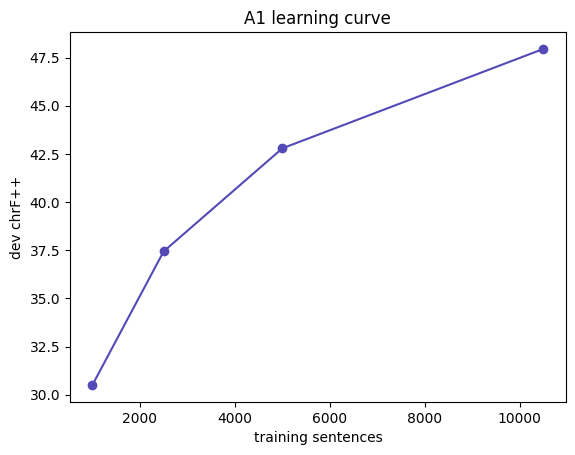

In [22]:
# 13. OPTIONAL learning curve: how much does A1 depend on the amount of data? (one seed, takes a while) -------------
RUN_LEARNING_CURVE = True
if RUN_LEARNING_CURVE and not SMOKE:
    lc = []
    for n in (1000, 2500, 5000):
        r = train_one_seed(CFG['seeds'][0], n_train=n, tag=f'LC{n}'); lc.append(dict(n_train=n, dev_chrfpp=r['dev_chrfpp'], dev_bleu=r['dev_bleu']))
    full = [r for r in results if r['seed'] == CFG['seeds'][0]][0]
    lc.append(dict(n_train=full['n_train'], dev_chrfpp=full['dev_chrfpp'], dev_bleu=full['dev_bleu']))
    lc = pd.DataFrame(lc); display(lc); lc.to_csv(f'{REPORT_DIR}/learning_curve.csv', index=False)
    plt.plot(lc['n_train'], lc['dev_chrfpp'], marker='o', color='#534AB7'); plt.xlabel('training sentences'); plt.ylabel('dev chrF++')
    plt.title('A1 learning curve'); plt.savefig(f'{REPORT_DIR}/figures/learning_curve.png', dpi=150, bbox_inches='tight'); plt.show()

In [23]:
# 14. Phase 2 gate and run record --------------------------------------------------------------------------------
a1_dev = a1['dev_chrfpp'].astype(float)
gain = a1_dev.mean() - float(per_seed.iloc[0]['dev_chrfpp'])
print(f'A1 vs A0 on dev chrF++: +{gain:.1f}   | std over seeds: {a1_dev.std(ddof=0):.2f}')
print('GATE (my suggested thresholds): A1 clearly above A0 (> +5 chrF++) and seed std small (< 1.0):',
      'PASS' if (gain > 5 and a1_dev.std(ddof=0) < 1.0) else 'CHECK (see the hints in the next cell)')

record = dict(date=datetime.date.today().isoformat(), smoke=SMOKE, config=CFG, python=platform.python_version(),
              torch=torch.__version__, transformers=transformers.__version__, gpu=torch.cuda.get_device_name(0),
              n_train=len(train), n_dev=len(dev), n_test=len(test), vocab_size=len(tok),
              results=results, best_steps={r['seed']: r['best_step'] for r in results})
json.dump(record, open(f'{REPORT_DIR}/phase2_run_record.json', 'w'), indent=2, default=str)
with open(f'{REPORT_DIR}/baseline_results.md', 'w', encoding='utf-8') as f:
    f.write('# Method A baseline results\n\n' + md_table(summary) + '\n\nPer seed:\n\n' + md_table(per_seed) + '\n')

A1 vs A0 on dev chrF++: +39.9   | std over seeds: 0.21
GATE (my suggested thresholds): A1 clearly above A0 (> +5 chrF++) and seed std small (< 1.0): PASS


**If the gate says CHECK**
- *A1 barely above A0:* look at cell 6 — a high `tokens_per_word` or `unk_rate_pct` on the source side means the Arabic-trained tokenizer is a poor fit for Latin Darija. Tell me the numbers; the fix may be another pretrained model.
- *Large std over seeds:* lower the learning rate (3e-5), raise `patience`, or add epochs.
- *Out of GPU memory:* set `batch_size=16` and `grad_accum=2`.
- *Dev score rising until the last epoch:* raise `max_epochs`.

In [25]:
# 15. Commit the small reports to GitHub (Colab only) ---------------------------------------------------------------
if IN_COLAB and not SMOKE:
    !git -C {REPO_DIR} config user.name "{siaelkhattat}"
    !git -C {REPO_DIR} config user.email "{assia194921@gmail.com}"
    !git -C {REPO_DIR} add reports
    !git -C {REPO_DIR} commit -m "Phase 2: baseline (Method A) results"
    !git -C {REPO_DIR} {AUTH} push
# Checkpoints and predictions stay on Drive (RUN_DIR). Save this notebook with File > Save a copy in GitHub > notebooks/02_baseline.ipynb

fatal: cannot change to '{REPO_DIR}': No such file or directory
fatal: cannot change to '{REPO_DIR}': No such file or directory
Author identity unknown

*** Please tell me who you are.

Run

  git config --global user.email "you@example.com"
  git config --global user.name "Your Name"

to set your account's default identity.
Omit --global to set the identity only in this repository.

fatal: unable to auto-detect email address (got 'root@7d25b573b50d.(none)')
fatal: cannot change to '{REPO_DIR}': No such file or directory
